# RAG: Baseline Retrieval vs. Cross-Encoder Re-Ranking

**Document:** IFAB *Laws of the Game 2026/27* (260-page official football rulebook)

This notebook builds two retrieval-augmented generation (RAG) pipelines over the **same chunked corpus** and compares them:

| | Pipeline 1 – Baseline | Pipeline 2 – Re-Ranking |
|---|---|---|
| Stage 1 | Bi-encoder (`all-MiniLM-L6-v2`) → FAISS inner-product search → Top 10 | *same Top 10 candidates* |
| Stage 2 | – | Cross-encoder (`ms-marco-MiniLM-L-6-v2`) scores all 10 (query, chunk) pairs, re-sorts |
| Context to LLM | Top 3 by cosine similarity | Top 3 by cross-encoder score |
| Generator | `qwen2.5:7b` (local, Ollama), identical prompt | same |

**Sections**
1. Setup & configuration
2. Loading and cleaning the PDF
3. Chunking
4. Indexing (bi-encoder + FAISS)
5. The two pipelines
6. Failure-mode analysis (stress tests) – rank shifts + Answer 1 vs Answer 2
7. Query-bank evaluation (Hit@3 / MRR over a wider set of queries)
8. Latency profiling
9. Scaling experiment (why not cross-encode everything?)
10. Report

**How to run:** create a Python env with the packages in `requirements.txt`, install [Ollama](https://ollama.com) and run `ollama pull qwen2.5:7b`, then run all cells. The PDF is downloaded automatically if `data/` does not contain it.

## 1. Setup & configuration

In [1]:
import os
# faiss and torch each ship an OpenMP runtime on Windows; this flag stops them from clashing
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")

import re, json, time, statistics, urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import faiss
import pymupdf                      # PyMuPDF, for PDF text extraction
import ollama                       # client for the local Ollama LLM server
from sentence_transformers import SentenceTransformer, CrossEncoder
import matplotlib.pyplot as plt

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)

# ---- configuration -------------------------------------------------------
PDF_URL   = "https://downloads.theifab.com/downloads/laws-of-the-game-202627-single-pages?l=en"
PDF_PATH  = Path("data/laws_of_the_game_2026_27.pdf")
RESULTS   = Path("results"); RESULTS.mkdir(exist_ok=True)

BI_ENCODER_NAME    = "sentence-transformers/all-MiniLM-L6-v2"   # dense bi-encoder
CROSS_ENCODER_NAME = "cross-encoder/ms-marco-MiniLM-L-6-v2"     # re-ranker
LLM_NAME           = "qwen2.5:7b"                               # served by Ollama

TOP_K = 10      # candidates retrieved by the bi-encoder
TOP_N = 3       # chunks passed to the LLM
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print("torch", torch.__version__, "| device:", DEVICE,
      "|", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "")

torch 2.14.1+cu126 | device: cuda | NVIDIA GeForce RTX 4060 Laptop GPU


In [2]:
# Download the rulebook once (single-page edition; the 'double pages' edition puts two pages
# side by side, which scrambles text extraction).
if not PDF_PATH.exists():
    PDF_PATH.parent.mkdir(exist_ok=True)
    urllib.request.urlretrieve(PDF_URL, PDF_PATH)
doc = pymupdf.open(PDF_PATH)
print(f"{PDF_PATH.name}: {doc.page_count} pages, {PDF_PATH.stat().st_size/1e6:.1f} MB")

laws_of_the_game_2026_27.pdf: 260 pages, 23.4 MB


## 2. Loading and cleaning the PDF

The PDF's printed page numbers equal the PDF page index, so the **Contents** page (pp. 6–7) gives the page range of every section. Each chunk is tagged with its section, e.g. *Law 12 – Fouls and Misconduct*, which lets us cite where a retrieved chunk came from.

Cleaning steps:
* drop the cover, contents and back-matter pages, and the near-empty "Law N" divider/illustration pages (< 15 words);
* remove the page number on the first line and the running footer `Laws of the Game 2026/27 | Law X | ...`;
* remove stray control characters that PyMuPDF emits for some bullet glyphs.

Note: the book includes a **"Law changes 2026/27"** section that reprints old wording which the PDF marks as deleted with ~~strikethrough~~. Text extraction cannot see the strikethrough, so deleted rules read as current. This section is kept on purpose: it is a realistic source of distractor chunks (see §6.2).

In [3]:
# (first page, section title) - taken from the Contents pages of the PDF
SECTIONS = [
    (9, "About the Laws"), (16, "Notes and modifications"), (20, "General modifications"),
    (22, "Time-limited substitution protocol"), (24, "Off-field treatment and assessment protocol"),
    (26, "Throw-in and goal-kick countdown protocol"), (28, "'Only the captain' guidelines"),
    (32, "Guidelines for temporary dismissals (sin bins)"), (36, "Guidelines for return substitutes"),
    (38, "Additional permanent concussion substitutions protocol"),
    (45, "Law 1 - The Field of Play"), (55, "Law 2 - The Ball"), (59, "Law 3 - The Players"),
    (67, "Law 4 - The Players' Equipment"), (73, "Law 5 - The Referee"),
    (85, "Law 6 - The Other Match Officials"), (93, "Law 7 - The Duration of the Match"),
    (97, "Law 8 - The Start and Restart of Play"), (101, "Law 9 - The Ball in and out of Play"),
    (103, "Law 10 - Determining the Outcome of a Match"), (109, "Law 11 - Offside"),
    (115, "Law 12 - Fouls and Misconduct"), (131, "Law 13 - Free Kicks"),
    (135, "Law 14 - The Penalty Kick"), (141, "Law 15 - The Throw-in"),
    (145, "Law 16 - The Goal Kick"), (149, "Law 17 - The Corner Kick"),
    (152, "Video assistant referee (VAR) protocol"), (162, "FIFA Quality Programme"),
    (166, "Law changes 2026/27"), (194, "Glossary"),
    (208, "Practical guidelines for match officials"),
]
FIRST_PAGE, LAST_PAGE = 9, 239          # skip cover/contents and the blank back pages

def section_for(page):
    """Section title that a given page belongs to."""
    title = SECTIONS[0][1]
    for start, t in SECTIONS:
        if page >= start:
            title = t
    return title

FOOTER = re.compile(r"^Laws of the Game 2026/27\s*\|.*$")
CTRL   = re.compile(r"[\x00-\x08\x0b-\x1f­]")

def clean_page(text):
    """Return the cleaned, non-empty lines of one page."""
    lines = [l.replace(" ", " ").replace("\t", " ").strip() for l in text.split("\n")]
    out = []
    for i, line in enumerate(lines):
        line = CTRL.sub("", line).strip()
        if not line:
            continue
        if i == 0 and re.fullmatch(r"\d{1,3}", line):   # page number
            continue
        if FOOTER.match(line):                         # running footer
            continue
        out.append(line)
    return out

# every content line with its page and section
lines = []
for pno in range(FIRST_PAGE, LAST_PAGE + 1):
    text = doc[pno - 1].get_text()
    if len(text.split()) < 15:            # divider / full-page illustration
        continue
    for line in clean_page(text):
        lines.append({"page": pno, "section": section_for(pno), "line": line})

print(f"{len(lines)} text lines kept from {len({l['page'] for l in lines})} pages")

4447 text lines kept from 184 pages


## 3. Chunking

Structure-aware chunking:
1. Split the text into **units** at section boundaries and at numbered sub-headings such as `3. Substitution procedure`, so a chunk never mixes two different rules.
2. Inside a unit, split into sentences (bullets count as sentences) and pack them into chunks of about **120 words**, with **one sentence of overlap** between consecutive chunks. A clause cut at a chunk edge then still appears whole in one chunk.
3. Hard-cap very long bullet lists at 50 words per "sentence", so no chunk exceeds MiniLM's 256-token input window (longer text would be silently truncated before embedding).

Both pipelines use exactly this list of chunks.

In [4]:
SUBHEAD   = re.compile(r"^(\d{1,2})\.\s+([A-Z].{2,80})$")       # e.g. "3. Substitution procedure"
SENT_SPLIT = re.compile(r"(?<=[.!?;:])\s+(?=[A-Z‘'(•])|\s+(?=•)")
STARTS_NEW = re.compile(r"^[•–]")

def build_units(lines):
    """Group lines into (section, sub-section) units."""
    units, cur, sub = [], None, ""
    for row in lines:
        m = SUBHEAD.match(row["line"])
        new_section = cur is None or cur["section"] != row["section"]
        if new_section or m:
            sub = f"{m.group(1)}. {m.group(2)}" if m else ("" if new_section else sub)
            cur = {"section": row["section"], "subsection": sub, "lines": [], "pages": []}
            units.append(cur)
            if m:                      # heading line itself becomes metadata, not text
                continue
        cur["lines"].append(row["line"]); cur["pages"].append(row["page"])
    return units

def unit_sentences(unit, max_sent_words):
    """Sentences of a unit, each with the page it starts on."""
    sents = []
    for line, pno in zip(unit["lines"], unit["pages"]):
        for k, part in enumerate(p for p in SENT_SPLIT.split(line) if p.strip()):
            prev_open = sents and not sents[-1][0].rstrip().endswith((".", "!", "?", ";", ":"))
            if k == 0 and prev_open and not STARTS_NEW.match(part):
                sents[-1] = (sents[-1][0] + " " + part, sents[-1][1])   # line wraps mid-sentence
            else:
                sents.append((part, pno))
    capped = []                                                          # cap long bullet runs
    for s, pno in sents:
        w = s.split()
        capped += [(" ".join(w[i:i + max_sent_words]), pno) for i in range(0, len(w), max_sent_words)]
    return capped

def make_chunks(units, target_words=120, overlap_sents=1, max_sent_words=50):
    chunks = []
    for u in units:
        sents = unit_sentences(u, max_sent_words)
        if sum(len(s.split()) for s, _ in sents) < 8:
            continue
        buf, fresh = [], 0
        def flush():
            chunks.append({"section": u["section"], "subsection": u["subsection"],
                           "page": buf[0][1], "text": " ".join(s for s, _ in buf)})
        for s in sents:
            buf.append(s); fresh += 1
            if sum(len(x[0].split()) for x in buf) >= target_words:
                flush()
                buf, fresh = buf[-overlap_sents:] if overlap_sents else [], 0
        if fresh:                      # leftover sentences not yet emitted
            flush()
    for i, c in enumerate(chunks):
        c["id"] = i
        c["header"] = c["section"] + (f" > {c['subsection']}" if c["subsection"] else "")
    return chunks

chunks = make_chunks(build_units(lines))
lens = np.array([len(c["text"].split()) for c in chunks])
print(f"{len(chunks)} chunks | words per chunk: min {lens.min()}, median {int(np.median(lens))}, max {lens.max()}")
pd.DataFrame(chunks)[["id", "header", "page", "text"]].sample(4, random_state=1)

405 chunks | words per chunk: min 8, median 125, max 168


,id,header,page,text
361,361,Practical guidelines for match officials > 1. General positioning and movement,210,• Staying towards the outside of the play makes it easier to keep play and the lead AR in the referee’s field of vis...
62,62,Law 1 - The Field of Play > 6. The penalty area,48,"Two lines are drawn at right angles to the goal line, 16.5 m (18 yds) from the inside of each goalpost. These lines ..."
320,320,Law changes 2026/27 > 2. Offences and sanctions,184,"If a team is deliberately delaying their goal kick, the referee will whistle, signal for the goal kick to be taken a..."
92,92,Law 3 - The Players > 5. Offences and sanctions,63,• the player being substituted must still leave the field of play; they are cautioned only if they excessively delay...


## 4. Indexing with the bi-encoder

Each chunk is embedded **independently** by `all-MiniLM-L6-v2` (384-dim). Vectors are L2-normalised, so the inner product in a `faiss.IndexFlatIP` equals cosine similarity. The flat index does exact (brute-force) search, so the baseline's errors come from the embedding model, not from approximate search.

In [5]:
bi_encoder    = SentenceTransformer(BI_ENCODER_NAME, device=DEVICE)
cross_encoder = CrossEncoder(CROSS_ENCODER_NAME, device=DEVICE)

chunk_texts = [c["text"] for c in chunks]

t0 = time.perf_counter()
embeddings = bi_encoder.encode(chunk_texts, batch_size=64, normalize_embeddings=True,
                               convert_to_numpy=True, show_progress_bar=False).astype("float32")
index = faiss.IndexFlatIP(embeddings.shape[1])
index.add(embeddings)
index_build_s = time.perf_counter() - t0
print(f"Indexed {index.ntotal} chunks of dim {embeddings.shape[1]} in {index_build_s:.2f}s (one-off, offline cost)")

Indexed 405 chunks of dim 384 in 1.53s (one-off, offline cost)


## 5. The two pipelines

* `retrieve()` – Stage 1: embed the query and take the Top 10 chunks by cosine similarity.
* `rerank()` – Stage 2: score each of the 10 `(query, chunk)` pairs with the cross-encoder, then sort by that score in descending order.
* `generate()` – identical prompt for both pipelines; only the 3 context chunks differ.

The prompt tells the model to answer **only** from the passages. Otherwise `qwen2.5` could answer from its own football knowledge and hide retrieval failures.

In [6]:
def retrieve(query, k=TOP_K):
    """Stage 1 (bi-encoder): Top-k (chunk_id, cosine) pairs."""
    q = bi_encoder.encode([query], normalize_embeddings=True, convert_to_numpy=True).astype("float32")
    scores, ids = index.search(q, k)
    return [(int(i), float(s)) for i, s in zip(ids[0], scores[0])]

def rerank(query, candidates, model=None):
    """Stage 2 (cross-encoder): re-score the candidates jointly with the query and sort descending."""
    model = model or cross_encoder
    ce_scores = model.predict([(query, chunk_texts[i]) for i, _ in candidates], show_progress_bar=False)
    order = np.argsort(-ce_scores)
    return [(candidates[j][0], float(ce_scores[j])) for j in order]

SYSTEM_PROMPT = (
    "You answer questions about the IFAB Laws of the Game 2026/27. "
    "Use ONLY the numbered context passages. Do not use outside knowledge. "
    "Cite the passage numbers you rely on, like [2]. If the passages do not contain the answer, reply exactly: "
    "\"The provided context does not answer this question.\""
)

def build_prompt(query, chunk_ids):
    context = "\n\n".join(
        f"[{n}] ({chunks[i]['header']}, p.{chunks[i]['page']})\n{chunks[i]['text']}"
        for n, i in enumerate(chunk_ids, start=1))
    return f"Context passages:\n{context}\n\nQuestion: {query}\nAnswer in at most 3 sentences."

def generate(query, chunk_ids):
    """Call the local LLM deterministically (temperature 0, fixed seed)."""
    t0 = time.perf_counter()
    resp = ollama.chat(model=LLM_NAME,
                       messages=[{"role": "system", "content": SYSTEM_PROMPT},
                                 {"role": "user", "content": build_prompt(query, chunk_ids)}],
                       options={"temperature": 0, "seed": 42, "num_ctx": 4096})
    return resp["message"]["content"].strip(), time.perf_counter() - t0

def pipeline_1(query):
    """Baseline: bi-encoder Top 10 -> first 3 -> LLM (Answer 1)."""
    t0 = time.perf_counter()
    cands = retrieve(query)
    t_ret = time.perf_counter() - t0
    ctx = [i for i, _ in cands[:TOP_N]]
    answer, t_llm = generate(query, ctx)
    return {"candidates": cands, "context": ctx, "answer": answer, "t_retrieval": t_ret, "t_llm": t_llm}

def pipeline_2(query, candidates=None):
    """Re-ranking: same Top 10 -> cross-encoder -> top 3 -> LLM (Answer 2)."""
    t0 = time.perf_counter()
    cands = candidates if candidates is not None else retrieve(query)
    t1 = time.perf_counter()
    reranked = rerank(query, cands)
    t2 = time.perf_counter()
    ctx = [i for i, _ in reranked[:TOP_N]]
    answer, t_llm = generate(query, ctx)
    return {"reranked": reranked, "context": ctx, "answer": answer,
            "t_retrieval": t1 - t0, "t_rerank": t2 - t1, "t_llm": t_llm}

# warm-up: load the LLM into GPU memory and run each encoder once so timings below are fair
_ = generate("warm-up", [0]); _ = rerank("warm-up", retrieve("warm-up"))
print("models warm")

models warm


### Sanity check on a simple query

In [7]:
q = "How many substitutes can a team use in an official competition?"
p1 = pipeline_1(q); p2 = pipeline_2(q, p1["candidates"])
print("Baseline top-3 :", [chunks[i]["header"] for i in p1["context"]])
print("Re-ranked top-3:", [chunks[i]["header"] for i in p2["context"]])
print("\nAnswer 1:", p1["answer"]); print("\nAnswer 2:", p2["answer"])

Baseline top-3 : ['Law 3 - The Players > 2. Number of substitutions', 'Law 3 - The Players > 2. Number of substitutions', 'Law changes 2026/27 > 2. Number of substitutions']
Re-ranked top-3: ['Law 3 - The Players > 2. Number of substitutions', 'Law 3 - The Players > 2. Number of substitutions', 'General modifications']

Answer 1: In official competitions, the number of substitutes a team may use is determined by FIFA, the confederation, or the national football association and is capped at a maximum of five [1]. However, each team has a maximum of three substitution opportunities, with additional substitutions allowed at half-time if both teams make them simultaneously [1].

Answer 2: In official competitions, up to a maximum of five substitutes may be used by each team [1]. However, this number can vary for youth football, where the maximum will be determined by the national association, confederation or FIFA [3]. The conditions that apply to matches going into extra time are also det

## 6. Failure-mode analysis (stress testing)

**Method.** Each test query comes with a **gold evidence pattern**: a regex for the exact sentence in the rulebook that answers it, optionally limited to the section where the authoritative rule lives. A chunk is *gold* if it matches. This makes rank changes objective: for each query we report the best gold chunk's rank among the bi-encoder's Top 10 and its rank after cross-encoder re-ranking.

I screened ~70 candidate queries (§7 shows the reusable bank). The queries below were chosen because they show the failure categories from the assignment:

| Category | What goes wrong for a bi-encoder |
|---|---|
| Keyword trap / synonym | The query's words differ from the rulebook's terms (*protect the ball* vs *shield*, *fake an injury* vs *feigning / deceive*). Chunks with more lexical overlap but a different rule win on cosine. |
| Exception / corner case | The general rule (substitution procedure) outranks the restriction that applies only in special cases (return substitutions). |
| Negation / role limits | "*not* permitted", "*do not* touch": a single pooled vector barely changes when a "not" is added, so the general topic matches but the constraint gets lost. |
| Buried chunk (ranks 4–10) | All five cases also fall into this category: the right chunk is retrieved but sits below the cut-off of 3. |

§6.2 adds **limitation cases** where re-ranking does *not* help. They are useful for the report.

In [8]:
FAILURE_CASES = [
    dict(category="Keyword trap / synonym",
         query="Can a player use their body to protect the ball from an opponent?",
         gold=r"may shield the ball", section=None),
    dict(category="Keyword trap / synonym",
         query="What happens if a player fakes an injury to fool the referee?",
         gold=r"feign", section="Law 12"),
    dict(category="Exception / corner case",
         query="Can a substituted player come back on later in the game?",
         gold=r"return substitutions is only permitted", section=None),
    dict(category="Negation / role limit",
         query="Who is not permitted to approach the referee to discuss decisions?",
         gold=r"only the captains? .{0,40}(approach|allowed)", section=None),
    dict(category="Negation / constraint",
         query="Is a player in an offside position penalised if they do not touch the ball?",
         gold=r"only penalised on becoming involved in active play", section=None),
]

LIMITATION_CASES = [
    dict(category="Document-specific: stale (struck-through) text",
         query="Are players allowed to wear rings or earrings during a match?",
         gold=r"Accessories are permitted as long as", section="Law 4"),
    dict(category="Recall ceiling (gold outside Top 10)",
         query="Can a player who has been sent off stay in the technical area?",
         gold=r"sent off must leave the vicinity", section=None),
    dict(category="Re-ranker demotes the right chunk",
         query="If the ball bounces off the referee and goes into the net, does the goal count?",
         gold=r"touches a match official", section="Law 9"),
]

def gold_ids(case):
    return {c["id"] for c in chunks
            if re.search(case["gold"], c["text"], re.I) and (case["section"] is None or case["section"] in c["section"])}

def full_rank(query, ids):
    """Rank of the best gold chunk over the WHOLE corpus by cosine (to see how far outside the Top 10 it is)."""
    q = bi_encoder.encode([query], normalize_embeddings=True).astype("float32")
    _, order = index.search(q, index.ntotal)
    order = order[0].tolist()
    return min(order.index(g) + 1 for g in ids)

def rank_table(query, cands, reranked, ids):
    """Top-10 table: baseline rank, cross-encoder rank, scores, and whether the chunk is gold."""
    ce_rank  = {cid: r for r, (cid, _) in enumerate(reranked, start=1)}
    ce_score = dict(reranked)
    rows = [{"chunk": cid, "baseline_rank": r, "cosine": round(s, 3),
             "ce_rank": ce_rank[cid], "ce_score": round(ce_score[cid], 2),
             "gold": "★" if cid in ids else "", "section": chunks[cid]["header"][:60]}
            for r, (cid, s) in enumerate(cands, start=1)]
    return pd.DataFrame(rows).set_index("chunk")

In [9]:
def run_case(case, show=True):
    ids = gold_ids(case)
    assert ids, f"gold pattern matched no chunk: {case['gold']}"
    p1 = pipeline_1(case["query"])
    p2 = pipeline_2(case["query"], p1["candidates"])       # SAME Top-10 candidates
    base = [cid for cid, _ in p1["candidates"]]
    rer  = [cid for cid, _ in p2["reranked"]]
    b_rank = min((base.index(g) + 1 for g in ids if g in base), default=None)
    c_rank = min((rer.index(g) + 1 for g in ids if g in rer), default=None)
    best_gold = min(ids, key=lambda g: base.index(g) if g in base else 99)
    rec = {"category": case["category"], "query": case["query"], "gold_chunk": best_gold,
           "baseline_rank": b_rank if b_rank else f">10 (#{full_rank(case['query'], ids)})",
           "reranked_rank": c_rank if c_rank else "not in candidates",
           "answer_1": p1["answer"], "answer_2": p2["answer"],
           "ctx_1": p1["context"], "ctx_2": p2["context"],
           "t_llm_1": p1["t_llm"], "t_llm_2": p2["t_llm"]}
    if show:
        print("=" * 110)
        print(f"[{case['category']}]  {case['query']}")
        print(f"Gold chunk(s) {sorted(ids)}  |  baseline rank: {rec['baseline_rank']}  ->  re-ranked rank: {rec['reranked_rank']}")
        display(rank_table(case["query"], p1["candidates"], p2["reranked"], ids))
        print("Pipeline 1 context:", [chunks[i]["header"] for i in p1["context"]])
        print("Pipeline 2 context:", [chunks[i]["header"] for i in p2["context"]])
        print("\nANSWER 1 (baseline):\n", p1["answer"])
        print("\nANSWER 2 (re-ranked):\n", p2["answer"])
    return rec

### 6.1 Failure queries where re-ranking restores relevance

In [10]:
failure_results = [run_case(c) for c in FAILURE_CASES]

[Keyword trap / synonym]  Can a player use their body to protect the ball from an opponent?
Gold chunk(s) [187]  |  baseline rank: 10  ->  re-ranked rank: 1


,baseline_rank,cosine,ce_rank,ce_score,gold,section
chunk,,,,,,
186,1,0.564,9,0.53,,Law 12 - Fouls and Misconduct > 2. Indirect free kick
181,2,0.561,5,2.59,,Law 12 - Fouls and Misconduct > 1. Direct free kick
392,3,0.555,7,1.58,,Practical guidelines for match officials > 3. Holding an opp
204,4,0.555,4,3.27,,Law 12 - Fouls and Misconduct > 4. Disciplinary action
182,5,0.554,3,3.33,,Law 12 - Fouls and Misconduct > 1. Direct free kick
351,6,0.553,2,3.50,,Glossary
157,7,0.529,10,-5.00,,Law 9 - The Ball in and out of Play > 2. Ball in play
169,8,0.518,8,0.79,,Law 11 - Offside > 2. Offside offence
345,9,0.517,6,1.84,,Glossary


Pipeline 1 context: ['Law 12 - Fouls and Misconduct > 2. Indirect free kick', 'Law 12 - Fouls and Misconduct > 1. Direct free kick', 'Practical guidelines for match officials > 3. Holding an opponent']
Pipeline 2 context: ['Law 12 - Fouls and Misconduct > 2. Indirect free kick', 'Glossary', 'Law 12 - Fouls and Misconduct > 1. Direct free kick']

ANSWER 1 (baseline):
 According to Law 12 [1], a player can use their body to protect the ball from an opponent as long as it does not constitute playing in a dangerous manner or impeding the progress of an opponent without contact. The law allows actions like scissors or bicycle kicks if they are not dangerous to an opponent, implying that using one's body to shield the ball is generally permissible [1].

ANSWER 2 (re-ranked):
 Yes, a player may shield the ball by taking a position between an opponent and the ball if the ball is within playing distance and the opponent is not held off with the arms or body [1]. This action allows the player to

[Keyword trap / synonym]  What happens if a player fakes an injury to fool the referee?
Gold chunk(s) [195]  |  baseline rank: 4  ->  re-ranked rank: 1


,baseline_rank,cosine,ce_rank,ce_score,gold,section
chunk,,,,,,
121,1,0.644,2,0.75,,Law 5 - The Referee > 3. Powers and duties
189,2,0.613,8,-2.44,,Law 12 - Fouls and Misconduct > 4. Disciplinary action
325,3,0.613,3,-0.02,,Law changes 2026/27 > 2. Reviewable match-changing decisions
195,4,0.611,1,2.16,★,Law 12 - Fouls and Misconduct > 4. Disciplinary action
300,5,0.607,5,-1.08,,Law changes 2026/27 > 3. Powers and duties
326,6,0.606,6,-1.81,,Law changes 2026/27 > 2. Reviewable match-changing decisions
199,7,0.603,9,-2.46,,Law 12 - Fouls and Misconduct > 4. Disciplinary action
115,8,0.602,10,-2.55,,Law 5 - The Referee > 2. Decisions of the referee
193,9,0.595,4,-0.31,,Law 12 - Fouls and Misconduct > 4. Disciplinary action


...

,baseline_rank,cosine,ce_rank,ce_score,gold,section
chunk,,,,,,
32,1,0.622,2,5.39,,'Only the captain' guidelines
132,2,0.605,7,1.39,,Law 5 - The Referee > 7. Liability of match officials
265,3,0.600,4,4.74,,Video assistant referee (VAR) protocol > 4. Procedures
31,4,0.593,1,5.68,,'Only the captain' guidelines
29,5,0.580,5,3.01,★,'Only the captain' guidelines
30,6,0.578,3,4.83,★,'Only the captain' guidelines
253,7,0.577,8,-1.18,,Video assistant referee (VAR) protocol > 4. Only the referee
1,8,0.542,6,1.79,,About the Laws
271,9,0.534,9,-1.44,,Video assistant referee (VAR) protocol > 4. Procedures


Pipeline 1 context: ["'Only the captain' guidelines", 'Law 5 - The Referee > 7. Liability of match officials', 'Video assistant referee (VAR) protocol > 4. Procedures']
Pipeline 2 context: ["'Only the captain' guidelines", "'Only the captain' guidelines", "'Only the captain' guidelines"]

ANSWER 1 (baseline):
 Players other than the captain may be cautioned if they approach or surround the referee when not permitted to do so [1]. The referee has discretion over interactions with players other than the captain, such as when a player has committed an offence, been fouled, or is injured [1].

ANSWER 2 (re-ranked):
 Players other than the designated captain are not permitted to approach the referee when they are not allowed to do so [1]. The referee may instruct players not to approach them and may delay the restart of play to allow the captain(s) time to speak with their team-mates [2]. Players who approach or surround the referee without permission may be cautioned (yellow card) [1].


[Negation / constraint]  Is a player in an offside position penalised if they do not touch the ball?
Gold chunk(s) [169]  |  baseline rank: 6  ->  re-ranked rank: 3


,baseline_rank,cosine,ce_rank,ce_score,gold,section
chunk,,,,,,
392,1,0.839,1,10.21,,Practical guidelines for match officials > 3. Holding an opp
176,2,0.775,9,6.02,,Law 11 - Offside > 4. Offences and sanctions
173,3,0.774,5,7.66,,Law 11 - Offside > 2. Offside offence
174,4,0.755,4,8.11,,Law 11 - Offside > 2. Offside offence
175,5,0.744,10,5.90,,Law 11 - Offside > 3. No offence
169,6,0.736,3,8.37,★,Law 11 - Offside > 2. Offside offence
400,7,0.713,8,6.05,,Practical guidelines for match officials > 4. Offside
397,8,0.711,2,8.88,,Practical guidelines for match officials > 4. Offside
168,9,0.701,6,6.77,,Law 11 - Offside > 1. Offside position


Pipeline 1 context: ['Practical guidelines for match officials > 3. Holding an opponent', 'Law 11 - Offside > 4. Offences and sanctions', 'Law 11 - Offside > 2. Offside offence']
Pipeline 2 context: ['Practical guidelines for match officials > 3. Holding an opponent', 'Practical guidelines for match officials > 4. Offside', 'Law 11 - Offside > 2. Offside offence']

ANSWER 1 (baseline):
 An attacker in an offside position (A), not interfering with an opponent, does not touch the ball and cannot be penalised [1]. Therefore, if a player is in an offside position but does not interfere with play or touch the ball, they are not penalised for being offside.

ANSWER 2 (re-ranked):
 According to [1], a player in an offside position who does not interfere with play by touching the ball cannot be penalised for being offside. Similarly, [2] indicates that a player in an offside position is not penalised if they do not gain an advantage from their position, specifically mentioning that the player 

### 6.2 Limitation cases (re-ranking does not fix these)

In [11]:
limitation_results = [run_case(c) for c in LIMITATION_CASES]

[Document-specific: stale (struck-through) text]  Are players allowed to wear rings or earrings during a match?
Gold chunk(s) [100]  |  baseline rank: 2  ->  re-ranked rank: 2


,baseline_rank,cosine,ce_rank,ce_score,gold,section
chunk,,,,,,
294,1,0.669,1,5.99,,Law changes 2026/27 > 1. Safety
100,2,0.605,2,2.45,★,Law 4 - The Players' Equipment > 1. Safety
128,3,0.573,5,-1.27,,Law 5 - The Referee > 5. Referee’s equipment
302,4,0.551,7,-2.74,,Law changes 2026/27 > 5. Referee’s equipment
295,5,0.530,10,-8.53,,Law changes 2026/27 > 1. Safety
303,6,0.530,8,-3.47,,Law changes 2026/27 > 5. Referee’s equipment
104,7,0.489,6,-2.07,,Law 4 - The Players' Equipment > 4. Other equipment
131,8,0.479,3,0.27,,Law 5 - The Referee > 7. Liability of match officials
105,9,0.466,4,-0.63,,Law 4 - The Players' Equipment > 4. Other equipment


Pipeline 1 context: ['Law changes 2026/27 > 1. Safety', "Law 4 - The Players' Equipment > 1. Safety", 'Law 5 - The Referee > 5. Referee’s equipment']
Pipeline 2 context: ['Law changes 2026/27 > 1. Safety', "Law 4 - The Players' Equipment > 1. Safety", 'Law 5 - The Referee > 7. Liability of match officials']

ANSWER 1 (baseline):
 According to the context provided [1], rings and earrings fall under the category of jewellery which is forbidden, and must be removed by players before starting the match. These items are considered dangerous if not removed and are not permitted even when covered with tape [1].

ANSWER 2 (re-ranked):
 According to the amended text [1], all items of jewellery such as rings and earrings are forbidden and must be removed before the start of the match, as they are considered dangerous equipment. The use of 'jewellery' is noted to potentially include items that do not constitute traditional jewellery but still need to be removed due to safety concerns.


[Recall ceiling (gold outside Top 10)]  Can a player who has been sent off stay in the technical area?
Gold chunk(s) [201]  |  baseline rank: >10 (#67)  ->  re-ranked rank: not in candidates


,baseline_rank,cosine,ce_rank,ce_score,gold,section
chunk,,,,,,
119,1,0.604,5,3.00,,Law 5 - The Referee > 3. Powers and duties
299,2,0.574,6,1.41,,Law changes 2026/27 > 3. Powers and duties
300,3,0.564,7,1.34,,Law changes 2026/27 > 3. Powers and duties
120,4,0.561,10,-4.41,,Law 5 - The Referee > 3. Powers and duties
66,5,0.531,4,3.29,,Law 1 - The Field of Play > 9. The technical area
93,6,0.529,3,3.48,,Law 3 - The Players > 6. Players and substitutes sent off
21,7,0.517,8,-2.80,,Off-field treatment and assessment protocol
41,8,0.517,1,6.98,,Guidelines for temporary dismissals (sin bins)
53,9,0.513,9,-4.22,,Additional permanent concussion substitutions protocol


Pipeline 1 context: ['Law 5 - The Referee > 3. Powers and duties', 'Law changes 2026/27 > 3. Powers and duties', 'Law changes 2026/27 > 3. Powers and duties']
Pipeline 2 context: ['Guidelines for temporary dismissals (sin bins)', 'Law 5 - The Referee > 3. Powers and duties', 'Law 3 - The Players > 6. Players and substitutes sent off']

ANSWER 1 (baseline):
 The provided context does not answer this question.

ANSWER 2 (re-ranked):
 The provided context does not answer this question.


[Re-ranker demotes the right chunk]  If the ball bounces off the referee and goes into the net, does the goal count?
Gold chunk(s) [156, 157]  |  baseline rank: 3  ->  re-ranked rank: 4


,baseline_rank,cosine,ce_rank,ce_score,gold,section
chunk,,,,,,
158,1,0.646,1,2.73,,Law 10 - Determining the Outcome of a Match > 1. Goal scored
154,2,0.639,8,-2.42,,Law 8 - The Start and Restart of Play > 2. Dropped ball
156,3,0.637,4,0.05,★,Law 9 - The Ball in and out of Play > 1. Ball out of play
79,4,0.619,3,0.30,,Law 2 - The Ball > 2. Replacement of a defective ball
218,5,0.618,10,-5.08,,Law 13 - Free Kicks > 2. Procedure
244,6,0.614,5,-0.21,,Law 16 - The Goal Kick > 2. Offences and sanctions
153,7,0.602,7,-1.76,,Law 8 - The Start and Restart of Play > 2. Dropped ball
231,8,0.602,2,1.97,,Law 14 - The Penalty Kick > 2. Offences and sanctions
235,9,0.597,6,-0.44,,Law 15 - The Throw-in


Pipeline 1 context: ['Law 10 - Determining the Outcome of a Match > 1. Goal scored', 'Law 8 - The Start and Restart of Play > 2. Dropped ball', 'Law 9 - The Ball in and out of Play > 1. Ball out of play']
Pipeline 2 context: ['Law 10 - Determining the Outcome of a Match > 1. Goal scored', 'Law 14 - The Penalty Kick > 2. Offences and sanctions', 'Law 2 - The Ball > 2. Replacement of a defective ball']

ANSWER 1 (baseline):
 According to Law 9 - The Ball in and out of Play [3], if the ball touches a match official (the referee) and remains on the field of play, it is considered out of play under certain conditions. However, since the ball went into the net after bouncing off the referee, this situation does not fall under the specific scenarios where play would be restarted with a dropped ball [3]. Therefore, based on the provided context, the goal likely counts as the ball has entered the goal under these circumstances.

ANSWER 2 (re-ranked):
 According to Law 2 of the Laws of the Game 

For the stale-text case, here are the two competing chunks: the *Law changes* chunk (whose first sentences were deleted in the PDF with strikethrough) and the current Law 4 text.

In [12]:
for cid in [i for i, c in enumerate(chunks) if c["header"].startswith("Law changes") and "jewellery" in c["text"]][:1] + \
           sorted(gold_ids(LIMITATION_CASES[0])):
    print(f"--- chunk {cid} | {chunks[cid]['header']} | p.{chunks[cid]['page']}\n{chunks[cid]['text'][:600]}\n")

--- chunk 294 | Law changes 2026/27 > 1. Safety | p.173
Amended text A player must not use equipment or wear anything that is dangerous. All items of jewellery (necklaces, rings, bracelets, earrings, leather bands, rubber bands, etc.) are forbidden and must be removed. Using tape to cover jewellery is not permitted. Accessories are permitted as long as they are not dangerous and are safely and securely covered. Dangerous items must be removed and not taped or covered. The players must be inspected before the start of the match and substitutes before they enter the field of play. If a player is wearing or using unauthorised/ dangerous equipment or j

--- chunk 100 | Law 4 - The Players' Equipment > 1. Safety | p.67
A player must not use equipment or wear anything that is dangerous. Accessories are permitted as long as they are not dangerous and are safely and securely covered. Dangerous items must be removed and not taped or covered. The players must be inspected before the start of the

### 6.3 Rank-shift summary

In [13]:
rank_shifts = pd.DataFrame(failure_results + limitation_results)[
    ["category", "query", "gold_chunk", "baseline_rank", "reranked_rank"]]
rank_shifts.to_csv(RESULTS / "rank_shifts.csv", index=False)
with open(RESULTS / "answers.json", "w", encoding="utf-8") as f:
    json.dump(failure_results + limitation_results, f, indent=2, ensure_ascii=False)
rank_shifts

,category,query,gold_chunk,baseline_rank,reranked_rank
0,Keyword trap / synonym,Can a player use their body to protect the ball from an opponent?,187,10,1
1,Keyword trap / synonym,What happens if a player fakes an injury to fool the referee?,195,4,1
2,Exception / corner case,Can a substituted player come back on later in the game?,45,7,3
3,Negation / role limit,Who is not permitted to approach the referee to discuss decisions?,29,5,3
4,Negation / constraint,Is a player in an offside position penalised if they do not touch the ball?,169,6,3
5,Document-specific: stale (struck-through) text,Are players allowed to wear rings or earrings during a match?,100,2,2
6,Recall ceiling (gold outside Top 10),Can a player who has been sent off stay in the technical area?,201,>10 (#67),not in candidates
7,Re-ranker demotes the right chunk,"If the ball bounces off the referee and goes into the net, does the goal count?",156,3,4


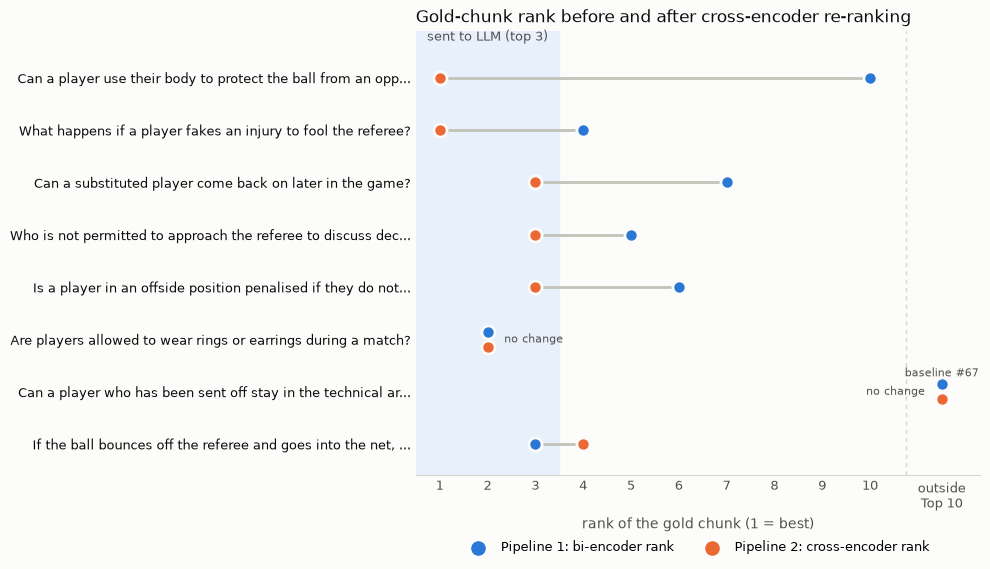

In [14]:
# Dumbbell chart: where the gold chunk sits before (blue) and after (orange) re-ranking.
# Ranks beyond the 10 candidates are drawn in an "outside Top 10" lane at x = 11.5.
BLUE, ORANGE, INK, MUTED, SURFACE = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#fcfcfb"
OUT_X = 11.5

def as_x(v):
    return v if isinstance(v, int) else OUT_X

df = rank_shifts.iloc[::-1].reset_index(drop=True)          # first case at the top
labels = [q if len(q) < 62 else q[:59] + "..." for q in df["query"]]
fig, ax = plt.subplots(figsize=(10, 0.55 * len(df) + 1.4), facecolor=SURFACE)
ax.set_facecolor(SURFACE)
ax.axvspan(0.5, 3.5, color="#e7f0fb", zorder=0)
ax.text(2, len(df) - 0.35, "sent to LLM (top 3)", ha="center", va="bottom", fontsize=9, color=MUTED)
ax.axvline(10.75, color="#d6d5d0", lw=1, ls=(0, (3, 3)))
for y, (b, c) in enumerate(zip(df["baseline_rank"], df["reranked_rank"])):
    bx, cx = as_x(b), as_x(c)
    dy = 0.14 if bx == cx else 0          # same rank before and after: draw the two dots one above the other
    ax.plot([bx, cx], [y, y], color="#c3c2b7", lw=2, zorder=1, solid_capstyle="round")
    ax.scatter(bx, y + dy, s=90, color=BLUE, edgecolor=SURFACE, linewidth=2, zorder=3)
    ax.scatter(cx, y - dy, s=90, color=ORANGE, edgecolor=SURFACE, linewidth=2, zorder=4)
    if bx == cx:
        right_edge = bx == OUT_X
        ax.annotate("no change", (bx, y), xytext=(-12 if right_edge else 12, 0), textcoords="offset points",
                    ha="right" if right_edge else "left", va="center", fontsize=8, color=MUTED)
    if not isinstance(b, int):
        ax.annotate("baseline " + str(b).split()[-1].strip("()"), (bx, y), xytext=(0, 11),
                    textcoords="offset points", ha="center", fontsize=8, color=MUTED)
ax.set_yticks(range(len(df)), labels, fontsize=9, color=INK)
ax.set_xticks(list(range(1, 11)) + [OUT_X], [str(i) for i in range(1, 11)] + ["outside\nTop 10"], fontsize=9, color=MUTED)
ax.set_xlim(0.5, 12.3); ax.set_ylim(-0.6, len(df) - 0.1)
ax.set_xlabel("rank of the gold chunk (1 = best)", color=MUTED)
ax.scatter([], [], s=90, color=BLUE, label="Pipeline 1: bi-encoder rank")
ax.scatter([], [], s=90, color=ORANGE, label="Pipeline 2: cross-encoder rank")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False, fontsize=9)
for s in ["top", "right", "left"]: ax.spines[s].set_visible(False)
ax.spines["bottom"].set_color("#d6d5d0"); ax.tick_params(length=0)
ax.set_title("Gold-chunk rank before and after cross-encoder re-ranking", loc="left", color=INK, fontsize=12)
plt.tight_layout(); plt.savefig(RESULTS / "rank_shift.png", dpi=150, facecolor=SURFACE); plt.show()

## 7. Query-bank evaluation

The hand-picked cases above show *that* re-ranking can help. To see *how often* it helps, the same gold-evidence method is run over a wider bank of 40 rulebook questions written in plain language. These are the queries I screened while building §6, including ones where nothing goes wrong. Metrics:
* **Hit@3**: the gold chunk is among the 3 chunks sent to the LLM;
* **MRR@10**: mean reciprocal rank of the gold chunk inside the Top 10 (0 if absent).

No LLM calls here: this is a retrieval-only evaluation.

In [15]:
QUERY_BANK = [  # (category, query, gold regex, section filter)
 ("keyword",   "Are players allowed to wear rings or earrings during a match?", r"Accessories are permitted as long as", "Law 4"),
 ("keyword",   "What happens if the keeper holds onto the ball for too long?", r"more than eight seconds", "Law 12"),
 ("keyword",   "If the ball bounces off the referee and goes into the net, does the goal count?", r"touches a match official", "Law 9"),
 ("keyword",   "Can a goal be scored straight from a throw-in?", r"goal cannot be scored directly from a throw-in", "Law 15"),
 ("keyword",   "Can the goalkeeper score by throwing the ball into the other team's net?", r"goalkeeper throws the ball directly into the opponents", None),
 ("keyword",   "Is it offside if a player gets the ball straight from a corner?", r"no offside offence if a player receives the ball directly", None),
 ("keyword",   "What happens if an indirect free kick goes straight into the net?", r"indirect free kick is kicked directly into the opponents", None),
 ("keyword",   "Is a goal allowed if a player accidentally scores with their arm?", r"directly from their hand/arm, even if accidental", "Law 12"),
 ("keyword",   "Can the goalkeeper be tackled while holding the ball?", r"goalkeeper cannot be challenged by an opponent", None),
 ("keyword",   "Is a bicycle kick allowed?", r"bicycle kick is permissible", None),
 ("keyword",   "Can a defender block an attacker's run when the ball is far away?", r"Impeding the progress of an opponent means", None),
 ("keyword",   "Can a player use their body to protect the ball from an opponent?", r"may shield the ball", None),
 ("keyword",   "If a player loses a boot and scores before putting it back on, does the goal stand?", r"footwear or shinguard is lost accidentally", None),
 ("keyword",   "Can a goalkeeper wear long trousers?", r"tracksuit bottoms", None),
 ("keyword",   "Do players have to wear shin pads?", r"shinguards", "Law 4"),
 ("keyword",   "Can a coach give tactical instructions to players through an earpiece?", r"electronic or communication equipment", None),
 ("keyword",   "Is a goal awarded if a dog runs onto the pitch and the ball goes in?", r"animal enters the field of play", None),
 ("keyword",   "What happens if a player fakes an injury to fool the referee?", r"feign", "Law 12"),
 ("keyword",   "Does the ball have to completely cross the line for a goal?", r"whole of the ball passes over the goal line", "Law 10"),
 ("keyword",   "Who gets punished if the referee cannot identify which coach misbehaved?", r"senior coach present in the technical area", None),
 ("exception", "Does an injured player always have to leave the field after being treated?", r"exceptions to the requirement to leave the field", "Law 5"),
 ("exception", "Is an injured player allowed to stay on the pitch if the opponent got a yellow card for the foul?", r"opponent is cautioned or sent off", "Law 5"),
 ("exception", "Can a player who is sent off be replaced by a substitute?", r"sent off before or after the kick-off may not be", "Law 3"),
 ("exception", "Can a goal be scored directly from a kick-off into the kicker's own goal?", r"directly enters the kicker.s goal, a corner kick", "Law 8"),
 ("exception", "Can a goal be scored directly from a dropped ball?", r"dropped ball enters the goal without touching at least two", None),
 ("exception", "Can a goalkeeper pick up the ball when a teammate passes it back with their foot?", r"deliberately kicked to the goalkeeper by a team-mate", None),
 ("exception", "Can the referee change a decision after play has restarted?", r"may not change a restart decision", None),
 ("exception", "Can a substituted player come back on later in the game?", r"return substitutions is only permitted", None),
 ("exception", "Can a player be sent off before the game has even started?", r"before entering the field of play at the start of the match", None),
 ("negation",  "Is leaving the pitch to celebrate a goal a yellow card offence?", r"Leaving the field of play to celebrate a goal is not a cautionable", None),
 ("negation",  "Which players are not allowed to take kicks in a penalty shoot-out?", r"(on the field of play at the end of|eligible to take kicks)", "Law 10"),
 ("negation",  "Can the match continue if one team is down to six players?", r"fewer than seven players", None),
 ("negation",  "Is a player in an offside position penalised if they do not touch the ball?", r"only penalised on becoming involved in active play", None),
 ("negation",  "Who is not permitted to approach the referee to discuss decisions?", r"only the captains? .{0,40}(approach|allowed)", None),
 ("negation",  "Is every touch of the ball with the arm a handball?", r"Not every touch of a player.s hand/arm", None),
 ("negation",  "Can a player who has been sent off stay in the technical area?", r"sent off must leave the vicinity", None),
 ("negation",  "Does the ball not need to be still when a free kick is taken?", r"must be stationary and the kicker", None),
 ("other",     "How long is a sin bin temporary dismissal?", r"10-15% of the total playing", None),
 ("other",     "What restart is given if the penalty taker touches the ball twice?", r"kicker deliberately touches the ball again", "Law 14"),
 ("other",     "How far must opponents be from the ball at a corner kick?", r"9\.15 m", "Law 17"),
]

bank_rows = []
for cat, q, gold, sec in QUERY_BANK:
    ids = gold_ids({"gold": gold, "section": sec})
    assert ids, q
    cands = retrieve(q); rer = rerank(q, cands)
    base = [c for c, _ in cands]; rr = [c for c, _ in rer]
    b = min((base.index(g) + 1 for g in ids if g in base), default=None)
    c = min((rr.index(g) + 1 for g in ids if g in rr), default=None)
    if b is None:            outcome = "gold outside Top 10 (unrecoverable)"
    elif b > 3 and c <= 3:   outcome = "fixed by re-ranking"
    elif b <= 3 and c > 3:   outcome = "broken by re-ranking"
    elif c < b:              outcome = "improved (same side of cut-off)"
    elif c > b:              outcome = "worse (same side of cut-off)"
    else:                    outcome = "unchanged"
    bank_rows.append({"category": cat, "query": q, "baseline_rank": b, "reranked_rank": c, "outcome": outcome})

bank = pd.DataFrame(bank_rows)
bank.to_csv(RESULTS / "query_bank_eval.csv", index=False)

def metrics(col):
    r = bank[col]
    return {"Hit@1": (r == 1).mean(), "Hit@3": (r <= 3).mean(),
            "MRR@10": r.apply(lambda x: 1 / x if pd.notna(x) else 0).mean()}
summary = pd.DataFrame({"Pipeline 1 (bi-encoder)": metrics("baseline_rank"),
                        "Pipeline 2 (+ cross-encoder)": metrics("reranked_rank")}).T.round(3)
display(summary)
display(bank["outcome"].value_counts().to_frame("queries"))
bank.sort_values("outcome")

,Hit@1,Hit@3,MRR@10
Pipeline 1 (bi-encoder),0.250,0.50,0.408
Pipeline 2 (+ cross-encoder),0.425,0.65,0.535


,queries
outcome,
unchanged,12
gold outside Top 10 (unrecoverable),10
fixed by re-ranking,8
improved (same side of cut-off),7
broken by re-ranking,2
worse (same side of cut-off),1


,category,query,baseline_rank,reranked_rank,outcome
2,keyword,"If the ball bounces off the referee and goes into the net, does the goal count?",3.0,4.0,broken by re-ranking
24,exception,Can a goal be scored directly from a dropped ball?,2.0,7.0,broken by re-ranking
39,other,How far must opponents be from the ball at a corner kick?,5.0,2.0,fixed by re-ranking
37,other,How long is a sin bin temporary dismissal?,5.0,3.0,fixed by re-ranking
33,negation,Who is not permitted to approach the referee to discuss decisions?,5.0,3.0,fixed by re-ranking
32,negation,Is a player in an offside position penalised if they do not touch the ball?,6.0,3.0,fixed by re-ranking
29,negation,Is leaving the pitch to celebrate a goal a yellow card offence?,4.0,2.0,fixed by re-ranking
27,exception,Can a substituted player come back on later in the game?,7.0,3.0,fixed by re-ranking
11,keyword,Can a player use their body to protect the ball from an opponent?,10.0,1.0,fixed by re-ranking
17,keyword,What happens if a player fakes an injury to fool the referee?,4.0,1.0,fixed by re-ranking


## 8. Latency profiling

Stages are timed separately with `time.perf_counter()`. All 40 bank queries are run 5 times each (200 measurements per stage) after warm-up, on an RTX 4060 Laptop GPU. The cross-encoder is also timed on **CPU**, because many deployments do not have a GPU for re-ranking. LLM generation time comes from the §6 runs (16 generations).

In [16]:
cross_encoder_cpu = CrossEncoder(CROSS_ENCODER_NAME, device="cpu")
rerank(QUERY_BANK[0][1], retrieve(QUERY_BANK[0][1]), model=cross_encoder_cpu)   # warm-up

REPEATS = 5
t_retr, t_rr_gpu, t_rr_cpu = [], [], []
for _ in range(REPEATS):
    for _, q, _, _ in QUERY_BANK:
        t0 = time.perf_counter(); cands = retrieve(q);                          t1 = time.perf_counter()
        rerank(q, cands);                                                        t2 = time.perf_counter()
        rerank(q, cands, model=cross_encoder_cpu);                               t3 = time.perf_counter()
        t_retr.append(t1 - t0); t_rr_gpu.append(t2 - t1); t_rr_cpu.append(t3 - t2)

llm_1 = [r["t_llm_1"] for r in failure_results + limitation_results]
llm_2 = [r["t_llm_2"] for r in failure_results + limitation_results]

def stats_ms(xs):
    xs = np.array(xs) * 1000
    return {"mean (ms)": xs.mean(), "median (ms)": np.median(xs), "p95 (ms)": np.percentile(xs, 95)}

retr_gpu = np.array(t_retr) + np.array(t_rr_gpu)
retr_cpu = np.array(t_retr) + np.array(t_rr_cpu)
latency = pd.DataFrame({
    "Pipeline 1 retrieval (embed query + FAISS Top 10)":     stats_ms(t_retr),
    "Cross-encoder re-rank of 10 pairs (GPU)":               stats_ms(t_rr_gpu),
    "Cross-encoder re-rank of 10 pairs (CPU)":               stats_ms(t_rr_cpu),
    "Pipeline 2 retrieval total (GPU re-rank)":              stats_ms(retr_gpu),
    "Pipeline 2 retrieval total (CPU re-rank)":              stats_ms(retr_cpu),
    "LLM generation, Pipeline 1 (qwen2.5:7b)":               stats_ms(llm_1),
    "LLM generation, Pipeline 2 (qwen2.5:7b)":               stats_ms(llm_2),
}).T.round(1)
latency.to_csv(RESULTS / "latency.csv")
display(latency)

e2e_1 = np.median(t_retr) + np.median(llm_1)
e2e_2 = np.median(retr_gpu) + np.median(llm_2)
print(f"Retrieval-stage slowdown from re-ranking: x{np.median(retr_gpu)/np.median(t_retr):.1f} (GPU), "
      f"x{np.median(retr_cpu)/np.median(t_retr):.1f} (CPU)")
print(f"End-to-end median incl. LLM: Pipeline 1 = {e2e_1:.2f}s, Pipeline 2 = {e2e_2:.2f}s "
      f"(re-ranking adds {100*(np.median(retr_gpu)-np.median(t_retr))/e2e_1:.1f}% on GPU)")

,mean (ms),median (ms),p95 (ms)
Pipeline 1 retrieval (embed query + FAISS Top 10),10.0,9.4,13.9
Cross-encoder re-rank of 10 pairs (GPU),64.4,61.9,95.8
Cross-encoder re-rank of 10 pairs (CPU),125.0,122.8,158.9
Pipeline 2 retrieval total (GPU re-rank),74.4,71.6,108.2
Pipeline 2 retrieval total (CPU re-rank),134.9,133.0,170.1
"LLM generation, Pipeline 1 (qwen2.5:7b)",1623.2,1703.7,2536.0
"LLM generation, Pipeline 2 (qwen2.5:7b)",1769.1,1886.8,2108.2


Retrieval-stage slowdown from re-ranking: x7.6 (GPU), x14.2 (CPU)
End-to-end median incl. LLM: Pipeline 1 = 1.71s, Pipeline 2 = 1.96s (re-ranking adds 3.6% on GPU)


## 9. Scaling experiment: cross-encoding the whole corpus

To support the scaling question with data, we time **one** query scored against **every** chunk by the cross-encoder, compare it to the bi-encoder search over the same chunks, and extrapolate linearly to larger collections. The bi-encoder's corpus embeddings are computed once offline; at query time it only does one embedding plus a matrix product. The cross-encoder has to run a full transformer forward pass for every (query, chunk) pair, and it must do so again for every new query.

In [17]:
q = FAILURE_CASES[0]["query"]
all_pairs = [(q, t) for t in chunk_texts]

def timed(fn, n=3):
    fn(); ts = []
    for _ in range(n):
        t0 = time.perf_counter(); fn(); ts.append(time.perf_counter() - t0)
    return min(ts)

t_bi_full  = timed(lambda: retrieve(q, k=index.ntotal))
t_ce_gpu   = timed(lambda: cross_encoder.predict(all_pairs, batch_size=64, show_progress_bar=False))
t_ce_cpu   = timed(lambda: cross_encoder_cpu.predict(all_pairs, batch_size=64, show_progress_bar=False), n=1)

def human(s):
    for unit, size in [("days", 86400), ("h", 3600), ("min", 60), ("s", 1)]:
        if s >= size:
            return f"{s/size:,.1f} {unit}"
    return f"{s*1000:.0f} ms"

N = len(chunks)
sizes = [N, 10_000, 1_000_000, 100_000_000]
scale = pd.DataFrame({
    "corpus size (chunks)":                    [f"{n:,}" for n in sizes],
    "cross-encoder on ALL chunks, GPU":        [human(t_ce_gpu * n / N) for n in sizes],
    "cross-encoder on ALL chunks, CPU":        [human(t_ce_cpu * n / N) for n in sizes],
    "two-stage: re-rank Top 10 only, GPU":     [human(np.median(t_rr_gpu))] * len(sizes),
}).set_index("corpus size (chunks)")
print(f"Measured on this corpus ({N} chunks): bi-encoder search over all chunks {t_bi_full*1000:.1f} ms | "
      f"cross-encoder over all chunks {t_ce_gpu*1000:.0f} ms GPU / {t_ce_cpu*1000:.0f} ms CPU "
      f"({t_ce_gpu/np.median(t_rr_gpu):.0f}x the cost of re-ranking only the Top 10 on GPU)")
print("Rows beyond 405 chunks are linear extrapolations, per query. The two-stage cost stays flat because the")
print("first-stage vector search stays at milliseconds with an ANN index (IVF/HNSW) and only 10 pairs are cross-encoded.")
scale

Measured on this corpus (405 chunks): bi-encoder search over all chunks 9.8 ms | cross-encoder over all chunks 516 ms GPU / 6347 ms CPU (8x the cost of re-ranking only the Top 10 on GPU)
Rows beyond 405 chunks are linear extrapolations, per query. The two-stage cost stays flat because the
first-stage vector search stays at milliseconds with an ANN index (IVF/HNSW) and only 10 pairs are cross-encoded.


,"cross-encoder on ALL chunks, GPU","cross-encoder on ALL chunks, CPU","two-stage: re-rank Top 10 only, GPU"
corpus size (chunks),,,
405,516 ms,6.3 s,62 ms
"10,000",12.7 s,2.6 min,62 ms
"1,000,000",21.2 min,4.4 h,62 ms
"100,000,000",1.5 days,18.1 days,62 ms


## 10. Report

### 10.1 Bi-encoder vs cross-encoder

**Bi-encoder (`all-MiniLM-L6-v2`)**
- The question and each chunk are turned into vectors **separately**.
- We compare the vectors with cosine similarity.
- Chunk vectors are made once, before any question is asked. So search is very fast.
- Problem: the whole chunk is squeezed into one vector without knowing the question. Small but important words like "**not**", "**only**", or a synonym ("protect" vs "shield") get lost. It mostly finds chunks on the same *topic*.

**Cross-encoder (`ms-marco-MiniLM-L-6-v2`)**
- The question and the chunk are fed into the model **together**, as one input.
- Every word of the question can look at every word of the chunk (self-attention), and the model outputs one relevance score.
- So it can judge "does this chunk actually answer this question?", not just "is it on the same topic?".
- Problem: nothing can be prepared in advance. It has to run once for every (question, chunk) pair, which is slow.

### 10.2 Rank changes and answer comparison

"Rank" = position of the chunk that really answers the question (the *gold* chunk). Only the top 3 are given to the LLM.

| Question | Rank: baseline → re-ranked | Answer 1 (baseline) | Answer 2 (re-ranked) |
|---|---|---|---|
| Can a player use their body to **protect** the ball? (book uses the word "shield") | **#10 → #1** | Did not have the shielding rule. Guessed "yes" from an unrelated bicycle-kick sentence. | Gives the real rule: you can shield if the ball is within playing distance and you don't hold the opponent off with your arms. |
| What happens if a player **fakes** an injury? (book says "feigning") | **#4 → #1** | "The provided context does not answer this question." | Correct: yellow card for unsporting behaviour. |
| Can a substituted player come back on? (exception) | **#7 → #3** | "Yes, under specific circumstances". **Misses the key condition.** | Correct: only allowed in youth, veterans, disability and grassroots football. |
| Who is **not** allowed to approach the referee? (negation) | **#5 → #3** | Mostly correct (a related chunk was already #1). | Correct. All 3 chunks are now from the right guideline. Answer is about the same. |
| Is an offside player penalised if they do **not** touch the ball? (negation) | **#6 → #3** | Correct, but based on a picture caption. | Correct, and now the actual Law 11 rule is also in the context. |

**Did the baseline hallucinate?** Not really. Because the prompt says "use only the context", the baseline mostly **left things out**: it said "I don't know" (fake injury), missed an important condition (return substitutes), or guessed from weak evidence (shielding).

**Cases where re-ranking did NOT help**
- **Old deleted text in the PDF.** The "Law changes" section shows the *deleted* rule "all jewellery is forbidden" with a line through it. When we extract the text, the line-through is lost, so it looks like a real rule. Both pipelines put this chunk at #1, and **both answers wrongly say jewellery is forbidden**. A re-ranker checks relevance, not whether the text is still valid. This has to be fixed in data cleaning.
- **Right chunk not in the Top 10.** For "Can a sent-off player stay in the technical area?" the gold chunk was **#67**. The cross-encoder only sees the Top 10, so it can't help. This happened for **10 of 40** test questions.
- **Re-ranker made it worse.** "Ball bounces off the referee into the net": gold chunk went **#3 → #4**. Also, Answer 1 had the right chunk but still answered wrong ("goal counts"; the rule says dropped ball). So good retrieval does not always mean a good answer.

**On 40 test questions (§7):**

| | Bi-encoder only | + Cross-encoder |
|---|---|---|
| Gold chunk at #1 (Hit@1) | 25 % | 42.5 % |
| Gold chunk in top 3 (Hit@3) | 50 % | 65 % |
| MRR@10 | 0.41 | 0.54 |

Re-ranking fixed 8 questions, made 2 worse, and could not help the 10 where the gold chunk was outside the Top 10.

### 10.3 Latency

Median time, 40 questions × 5 runs, on an RTX 4060 laptop GPU (full table in §8):

| Step | Time |
|---|---|
| Pipeline 1 retrieval (embed question + FAISS Top 10) | ≈ 9 ms |
| Cross-encoder on 10 chunks (GPU / CPU) | ≈ 62 ms / ≈ 123 ms |
| **Pipeline 2 retrieval total** (GPU / CPU) | **≈ 72 ms / ≈ 133 ms** |
| LLM answer (`qwen2.5:7b`) | ≈ 1.7–1.9 s |

- Re-ranking makes retrieval about **8× slower on GPU** (about 14× on CPU).
- But the LLM takes almost all the time. Re-ranking adds only ≈ 62 ms to a ≈ 1.7 s answer, which is **less than 4 %**.
- (Numbers change by a few ms between runs.)

### 10.4 Why not use the cross-encoder on all chunks from the start?

- **It cannot be precomputed.** The cross-encoder needs the question and chunk together, so for every new question it must run on every chunk again. The bi-encoder makes chunk vectors once and then only does a fast vector search.
- **It is too slow.** Measured in §9: running it on all 405 chunks of this one book takes ≈ 0.5 s (GPU) / ≈ 6.3 s (CPU) per question. For 1 million chunks that would be ≈ 21 minutes (GPU) or ≈ 4.4 hours (CPU) **per question**. Re-ranking only the Top 10 stays at ≈ 62 ms no matter how big the collection is.
- **Two stages give the best of both.** The fast bi-encoder picks a small set of candidates; the accurate cross-encoder sorts only those.
- **Trade-off:** the cross-encoder can only reorder what the first stage found (in our tests, 25 % of gold chunks were outside the Top 10). In practice you retrieve more candidates (e.g. 50–100) or add keyword search (BM25) to the first stage.